# Sri Lankan Used Car Price Prediction

This notebook uses the **Sri Lanka Vehicle Ads Dataset** from Kaggle (ads from ikman.lk, Sept 2022 – Apr 2023).

Task: predict the **price of a used car** in Sri Lanka (**regression**).

---

In [42]:
DATA_DIR = "/kaggle/input/datasets/ivantha/sri-lanka-vehicle-ads-dataset/"

In [43]:
# Load dataset
import pandas as pd
import numpy as np
import ast

df = pd.read_csv(DATA_DIR + "vehicles.csv", low_memory=False)

print("Shape:", df.shape)
df.head()

Shape: (258888, 26)


,ad_title,ad_description,details,slug,title,type,price,timestamp,posted_date,deactivation_date,...,is_doorstep_delivery,is_dsd_applicable,is_member,is_authorized_dealer,is_featured_member,is_verified,membership_level,member_since,properties,user
0,Nissan Tiida Alternator in Maharagama | ikman,**TISSA AUTO PARTS** Dealer of used Japanese m...,NaN,nissan-tiida-alternator-for-sale-colombo-3,Nissan Tiida Alternator,for_sale,"Rs 18,000",23 Feb 11:35 pm,2023-02-23T23:35:10+05:30,2022-05-30T17:13:04.000Z,...,False,False,True,False,False,True,premium,September 2019,"{'Condition': 'Reconditioned', 'Part or Access...",a6681dea494390daa516a6d2bdcb36e08c318574a13413...
1,Axio 165 Tail Light in Kotte | ikman,Imported from Japan \n\nRight side available \...,NaN,axio-165-tail-light-for-sale-colombo-14,Axio 165 Tail Light,for_sale,"Rs 67,000",23 Feb 8:32 am,2023-02-23T08:32:44+05:30,2022-03-31T16:27:59.000Z,...,False,False,True,False,False,True,plus,June 2018,"{'Condition': 'Reconditioned', 'Part or Access...",5d99b8e45a1bb318079da7a36392d9025e1644cb49ecbf...
2,Axio 165 / 161 Head light in Kotte | ikman.lk,Imported from Japan \n\nAuto focus headlight a...,NaN,axio-165-161-head-light-for-sale-colombo,Axio 165 / 161 Head light,for_sale,"Rs 85,000",01 Dec 8:27 pm,2022-12-01T20:27:49+05:30,2022-03-31T14:03:57.000Z,...,False,False,True,False,False,True,plus,June 2018,"{'Condition': 'Reconditioned', 'Part or Access...",5d99b8e45a1bb318079da7a36392d9025e1644cb49ecbf...
3,Vigo side step ( Foot board) in Kottawa | ikman,Hilux Vigo side step\nBrand New Thaiwan\nGood ...,NaN,vigo-side-step-foot-board-for-sale-colombo,Vigo side step ( Foot board),for_sale,"Rs 47,000",04 Dec 2:47 pm,2022-12-04T14:47:27+05:30,2022-07-29T13:22:59.000Z,...,False,False,True,False,False,False,plus,February 2017,"{'Condition': 'New', 'Part or Accessory Type':...",634d93e14a62d9de7b400ee3679ae1d5506f4252ff0580...
4,Vigo Dickey Door Garnish Cover in Kottawa | i...,"Hilux Vigo ( 2005, 2009 ) dickey door garnish set",NaN,vigo-dickey-door-garnish-cover-for-sale-colombo-1,Vigo Dickey Door Garnish Cover,for_sale,"Rs 9,000",08 Dec 9:28 am,2022-12-08T09:28:04+05:30,2022-07-29T12:55:44.000Z,...,False,False,True,False,False,False,plus,February 2017,"{'Condition': 'New', 'Part or Accessory Type':...",634d93e14a62d9de7b400ee3679ae1d5506f4252ff0580...


In [44]:
# The dataset has all types of vehicle ads
df["category"].value_counts()

category
Motorbikes                  67642
Auto Parts & Accessories    67514
Cars                        48293
Three Wheelers              18117
Lorries & Trucks            12021
Auto Services               11625
Bicycles                    11315
Vans                         9486
Rentals                      7559
Tractors                     2450
Heavy Duty                   1862
Buses                         721
Boats & Water Transport       283
Name: count, dtype: int64

In [45]:
# Analyze the "type" feature.
# for_sale = selling a vehicle
# to_buy = looking for a vehicle
df["type"].value_counts()

type
for_sale    257731
to_buy        1157
Name: count, dtype: int64

In [46]:
# Here, I'm going to predict car price, so I keep only the "Cars" category. Removed "to_buy" ads too, because these are not real selling prices.
cars = df[(df["category"] == "Cars") & (df["type"] == "for_sale")].copy()

print("Cars for sale:", cars.shape)
counts = {"Raw data": len(df), "Cars for sale": len(cars)}   # to track rows removed

Cars for sale: (48090, 26)


In [47]:
# Analyze the car details from "properties" column. It has car details like brand, model, etc.
cars["properties"].iloc[0]

"{'Brand': 'Ssang Yong', 'Model': 'Rexton', 'Trim / Edition': 'Rexton Ultimate d/ca', 'Year of Manufacture': '2019', 'Condition': 'New', 'Transmission': 'Tiptronic', 'Body type': 'SUV / 4x4', 'Fuel type': 'Diesel', 'Engine capacity': '2,200 cc', 'Mileage': '0 km'}"

In [48]:
# Convert the text to a dictionary, then make each key a new column
props = cars["properties"].apply(ast.literal_eval).apply(pd.Series)
cars = pd.concat([cars, props], axis=1)

# The district is stored the same way in the 'area' column
cars["district"] = cars["area"].apply(ast.literal_eval).apply(lambda a: a["name"])

cars[["Brand", "Model", "Year of Manufacture", "Mileage", "Engine capacity", "price", "district"]].head()

,Brand,Model,Year of Manufacture,Mileage,Engine capacity,price,district
31,Ssang Yong,Rexton,2019,0 km,"2,200 cc","Rs 22,000,000",Colombo
1349,Toyota,CHR,2017,"9,000 km","1,200 cc","Rs 14,500,000",Colombo
1701,Toyota,Axio,2015,"24,000 km","1,500 cc","Rs 10,500,000",Colombo
1702,Daihatsu,Atrai Wagon,2016,"55,000 km",650 cc,"Rs 6,500,000",Colombo
1917,Mercedes Benz,C180,2010,"137,000 km","1,595 cc","Rs 11,500,000",Colombo


In [49]:
# Converting identified necessary text columns to numbers - price, mileage, capacity, Year of Manufacture
# If a value cannot be converted, use NaN

cars["price_lkr"]  = pd.to_numeric(cars["price"].str.replace("Rs", "").str.replace(",", ""), errors="coerce")
cars["mileage_km"] = pd.to_numeric(cars["Mileage"].str.replace("km", "").str.replace(",", ""), errors="coerce")
cars["engine_cc"]  = pd.to_numeric(cars["Engine capacity"].str.replace("cc", "").str.replace(",", ""), errors="coerce")
cars["year"]       = pd.to_numeric(cars["Year of Manufacture"], errors="coerce")

cars[["price_lkr", "mileage_km", "engine_cc", "year"]].describe()

,price_lkr,mileage_km,engine_cc,year
count,4.807600e+04,48090.000000,48090.000000,48090.000000
mean,7.978777e+06,111028.683157,1504.061946,2008.508255
std,1.450386e+07,77846.188145,705.814761,10.333306
min,1.000000e+00,0.000000,1.000000,1924.000000
25%,2.750000e+06,60000.000000,1000.000000,2004.000000
50%,5.075000e+06,98000.000000,1500.000000,2012.000000
75%,8.300000e+06,145629.000000,1800.000000,2016.000000
max,1.980000e+09,1000000.000000,10000.000000,2024.000000


In [50]:
# Checking missing values
cars[["price_lkr", "mileage_km", "engine_cc", "year", "Brand", "Model",
      "Condition", "Transmission", "Fuel type", "Body type"]].isnull().sum()

price_lkr         14
mileage_km         0
engine_cc          0
year               0
Brand              0
Model              0
Condition          0
Transmission       0
Fuel type          0
Body type       4179
dtype: int64

In [51]:
# As per above analysis, price has missing value. But it is also the target. Theerfore, instead of filling, need to remove those.
# As per above analysis, body type has missing values. Therefore, those are replaced by "Unknown".

cars = cars.dropna(subset=["price_lkr", "mileage_km", "engine_cc", "year"])

print("After removing missing values:", cars.shape)
counts["No missing price/numbers"] = len(cars)

After removing missing values: (48076, 41)


IQR lower limit : Rs -5,575,000
IQR upper limit : Rs 16,625,000
Cars IQR would remove (high): 4567
Cars below Rs 500,000 (typos): 321
Cars IQR would remove (low) : 0


Text(0, 0.5, 'Number of cars')

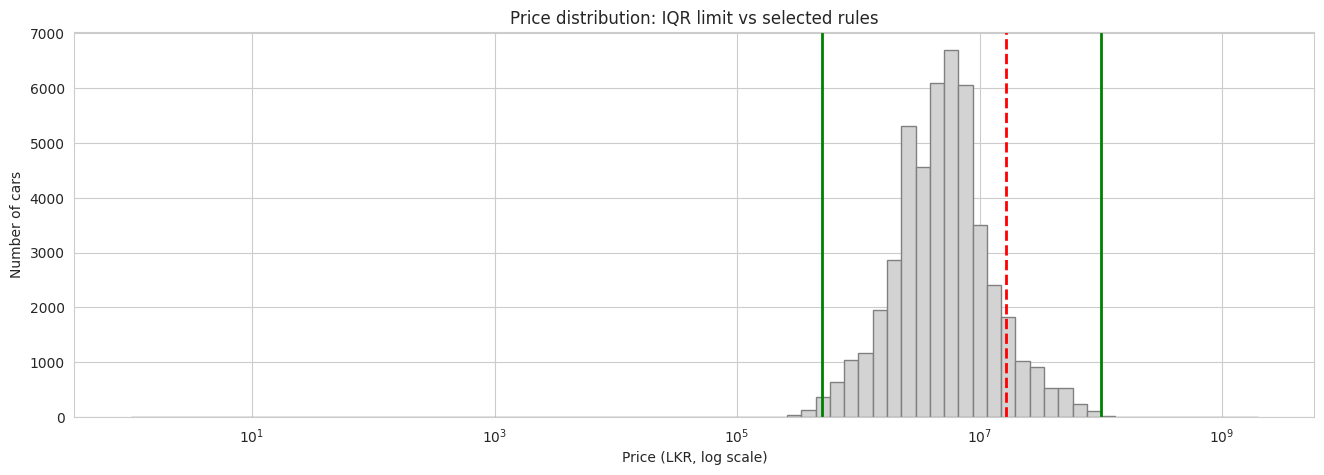

In [52]:
# Before removing outliers, check whether can we get IQR method to clean the prices.
import matplotlib.pyplot as plt

Q1 = cars["price_lkr"].quantile(0.25)
Q3 = cars["price_lkr"].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

iqr_removed = cars[cars["price_lkr"] > upper]

print("IQR lower limit : Rs", f"{lower:,.0f}")
print("IQR upper limit : Rs", f"{upper:,.0f}")
print("Cars IQR would remove (high):", len(iqr_removed))
print("Cars below Rs 500,000 (typos):", (cars["price_lkr"] < 500_000).sum())
print("Cars IQR would remove (low) :", (cars["price_lkr"] < lower).sum())

fig, axes = plt.subplots(1, 1, figsize=(16, 5))

bins = np.logspace(np.log10(cars["price_lkr"].min()), np.log10(cars["price_lkr"].max()), 80)
axes.hist(cars["price_lkr"], bins=bins, color="lightgray", edgecolor="gray")
axes.set_xscale("log")
axes.axvline(upper, color="red", linestyle="--", linewidth=2, label=f"IQR upper limit (Rs {upper/1e6:.1f}M)")
axes.axvline(500_000, color="green", linewidth=2, label="My rule: Rs 0.5M")
axes.axvline(100_000_000, color="green", linewidth=2, label="My rule: Rs 100M")
axes.set_title("Price distribution: IQR limit vs selected rules")
axes.set_xlabel("Price (LKR, log scale)")
axes.set_ylabel("Number of cars")

In [53]:
# Based on the above graph, it is not suitable to select IQR to detect and remove outliers.
# Therefore, outliers should be needed to remove in manually. Boundry values are selected based on the knowledge on the Sri Lanka car market.
cars = cars[
    (cars["price_lkr"] >= 500_000) & (cars["price_lkr"] <= 100_000_000) &
    (cars["year"] >= 1990) & (cars["year"] <= 2024) &
    (cars["mileage_km"] <= 500_000) &
    (cars["engine_cc"] >= 600) & (cars["engine_cc"] <= 6000) &
    (cars["Fuel type"].isin(["Petrol", "Diesel", "Hybrid"])) &
    (cars["Transmission"].isin(["Automatic", "Manual", "Tiptronic"]))
]

print("After removing outliers:", cars.shape)
counts["After outlier rules"] = len(cars)

After removing outliers: (43828, 41)


In [54]:
# Removing duplicate data - ads can have duplicates.
cars = cars.drop_duplicates(subset=["user", "Brand", "Model", "year", "mileage_km", "price_lkr"])

print("After removing duplicates:", cars.shape)
counts["After removing duplicates"] = len(cars)

After removing duplicates: (38462, 41)


In [55]:
# Fix a broken character in the body type
cars["Body type"] = cars["Body type"].str.replace("CoupÃ©/Sports", "Coupe/Sports")

# Fill missing body type
cars["Body type"] = cars["Body type"].fillna("Unknown")

# Remove extra spaces
cars["Brand"] = cars["Brand"].str.strip()
cars["Model"] = cars["Model"].str.strip()

cars["Body type"].value_counts()

Body type
Hatchback        14287
Saloon           11857
SUV / 4x4         7281
Unknown           3023
Station wagon     1270
MPV                386
Coupe/Sports       268
Convertible         90
Name: count, dtype: int64

In [56]:
# Create new features from the existing data -> car_age & seller_type.
cars["ad_year"] = cars["posted_date"].str[:4].astype(int)
cars["car_age"] = (cars["ad_year"] - cars["year"]).clip(lower=0)   # a 2024 car posted in 2023 → 0

cars["seller_type"] = cars["membership_level"].replace({"free": "Private", "plus": "Business", "premium": "Business"})

cars[["year", "ad_year", "car_age", "membership_level", "seller_type"]].head()

,year,ad_year,car_age,membership_level,seller_type
31,2019,2022,3,plus,Business
1349,2017,2023,6,premium,Business
1701,2015,2023,8,premium,Business
1702,2016,2022,6,plus,Business
1917,2010,2022,12,plus,Business


In [57]:
# Select final features to train the model.
cars = cars.rename(columns={
    "Brand": "brand", "Model": "model", "Condition": "condition",
    "Transmission": "transmission", "Fuel type": "fuel_type", "Body type": "body_type"
})

final_cols = ["brand", "model", "year", "car_age", "mileage_km", "engine_cc",
              "condition", "transmission", "fuel_type", "body_type",
              "district", "seller_type", "price_lkr"]

clean = cars[final_cols].reset_index(drop=True)

print("Final shape:", clean.shape)
clean.head()

Final shape: (38462, 13)


,brand,model,year,car_age,mileage_km,engine_cc,condition,transmission,fuel_type,body_type,district,seller_type,price_lkr
0,Ssang Yong,Rexton,2019,3,0,2200,New,Tiptronic,Diesel,SUV / 4x4,Colombo,Business,22000000.0
1,Toyota,CHR,2017,6,9000,1200,Reconditioned,Tiptronic,Petrol,Coupe/Sports,Colombo,Business,14500000.0
2,Toyota,Axio,2015,8,24000,1500,Reconditioned,Automatic,Hybrid,Saloon,Colombo,Business,10500000.0
3,Daihatsu,Atrai Wagon,2016,6,55000,650,Reconditioned,Automatic,Petrol,MPV,Colombo,Business,6500000.0
4,Mercedes Benz,C180,2010,12,137000,1595,Used,Tiptronic,Petrol,Saloon,Colombo,Business,11500000.0


In [58]:
# Check: no missing values
clean.isnull().sum()

brand           0
model           0
year            0
car_age         0
mileage_km      0
engine_cc       0
condition       0
transmission    0
fuel_type       0
body_type       0
district        0
seller_type     0
price_lkr       0
dtype: int64

In [59]:
clean.describe()

,year,car_age,mileage_km,engine_cc,price_lkr
count,38462.000000,38462.000000,38462.000000,38462.000000,3.846200e+04
mean,2010.214211,12.311216,106717.217617,1482.326166,7.592805e+06
std,7.326507,7.352054,62704.773771,653.317042,8.837843e+06
min,1990.000000,0.000000,0.000000,600.000000,5.000000e+05
25%,2006.000000,7.000000,60300.000000,1000.000000,2.950000e+06
50%,2012.000000,10.000000,97800.000000,1499.000000,5.175000e+06
75%,2016.000000,17.000000,143000.000000,1790.000000,8.150000e+06
max,2024.000000,33.000000,500000.000000,6000.000000,1.000000e+08


In [60]:
summary = pd.DataFrame(list(counts.items()), columns=["Step", "Rows"])
summary

,Step,Rows
0,Raw data,258888
1,Cars for sale,48090
2,No missing price/numbers,48076
3,After outlier rules,43828
4,After removing duplicates,38462


Exploratory Data Analysis (EDA)

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

sns.set_style("whitegrid")

In [62]:
# Target -> price.
# Check whether price is symmetric or skewed.

print(clean["price_lkr"].describe())

log_price = np.log1p(clean["price_lkr"])   # log(1 + price)

print("\nSkewness of price     :", round(clean["price_lkr"].skew(), 2))
print("Skewness of log(price):", round(log_price.skew(), 2))

count    3.846200e+04
mean     7.592805e+06
std      8.837843e+06
min      5.000000e+05
25%      2.950000e+06
50%      5.175000e+06
75%      8.150000e+06
max      1.000000e+08
Name: price_lkr, dtype: float64

Skewness of price     : 4.16
Skewness of log(price): 0.51


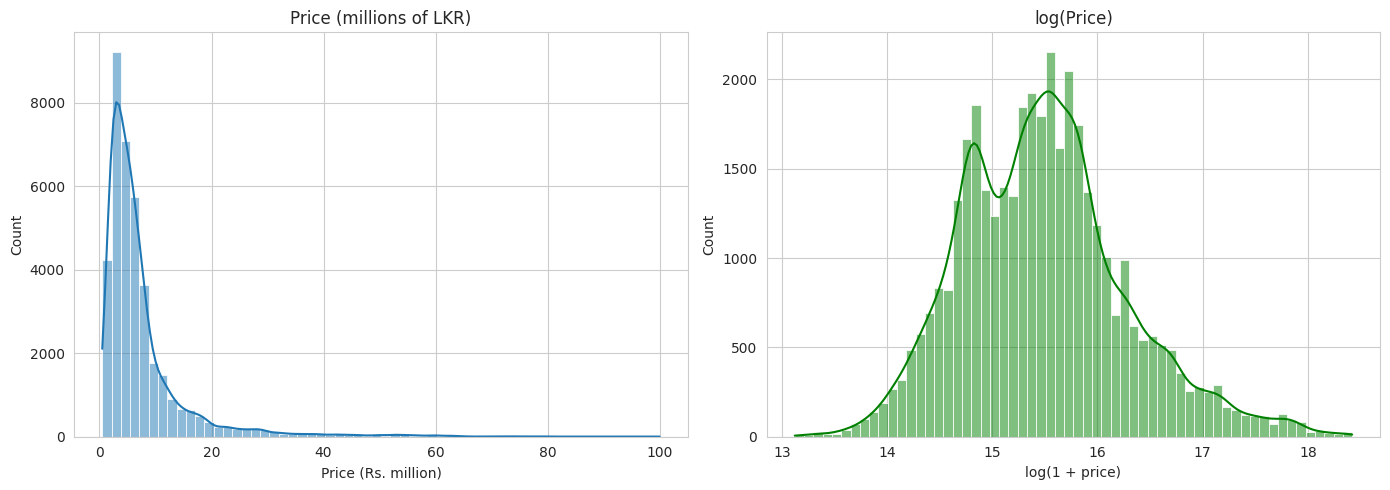

In [63]:
# Histograms: price vs log(price)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(clean["price_lkr"] / 1_000_000, bins=60, kde=True, ax=axes[0])
axes[0].set_title("Price (millions of LKR)")
axes[0].set_xlabel("Price (Rs. million)")

sns.histplot(log_price, bins=60, kde=True, ax=axes[1], color="green")
axes[1].set_title("log(Price)")
axes[1].set_xlabel("log(1 + price)")

plt.tight_layout()
plt.show()

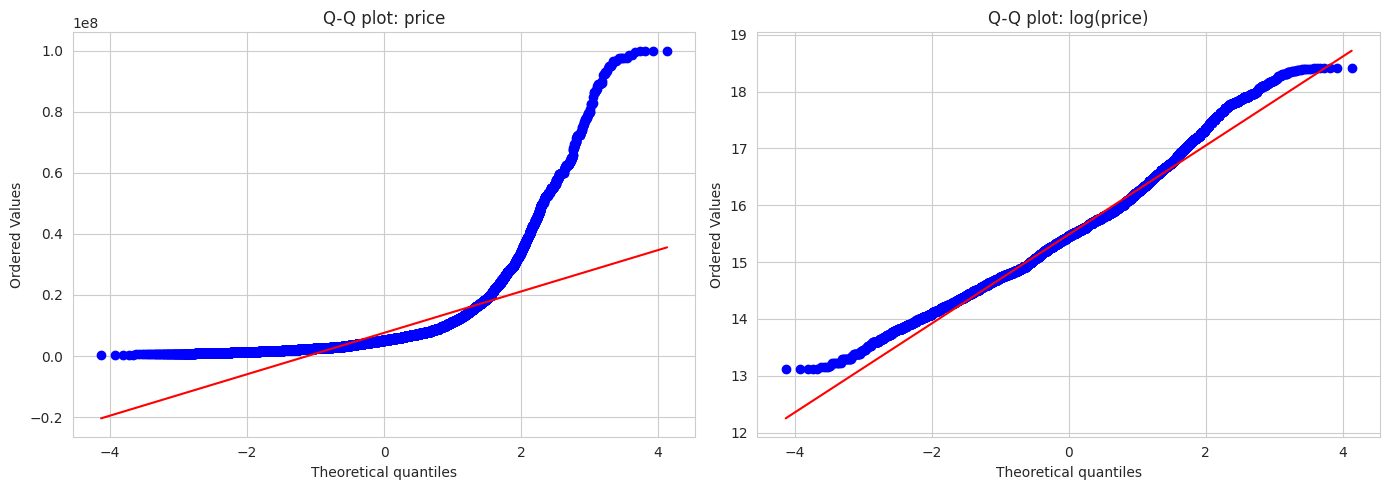

In [64]:
# Q-Q plots: if the points follow the red line, the data is close to normal
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

stats.probplot(clean["price_lkr"], dist="norm", plot=axes[0])
axes[0].set_title("Q-Q plot: price")

stats.probplot(log_price, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot: log(price)")

plt.tight_layout()
plt.show()

# Analyzing numeric features.

In [65]:
num_cols = ["year", "car_age", "mileage_km", "engine_cc"]

clean[num_cols].describe()

,year,car_age,mileage_km,engine_cc
count,38462.000000,38462.000000,38462.000000,38462.000000
mean,2010.214211,12.311216,106717.217617,1482.326166
std,7.326507,7.352054,62704.773771,653.317042
min,1990.000000,0.000000,0.000000,600.000000
25%,2006.000000,7.000000,60300.000000,1000.000000
50%,2012.000000,10.000000,97800.000000,1499.000000
75%,2016.000000,17.000000,143000.000000,1790.000000
max,2024.000000,33.000000,500000.000000,6000.000000


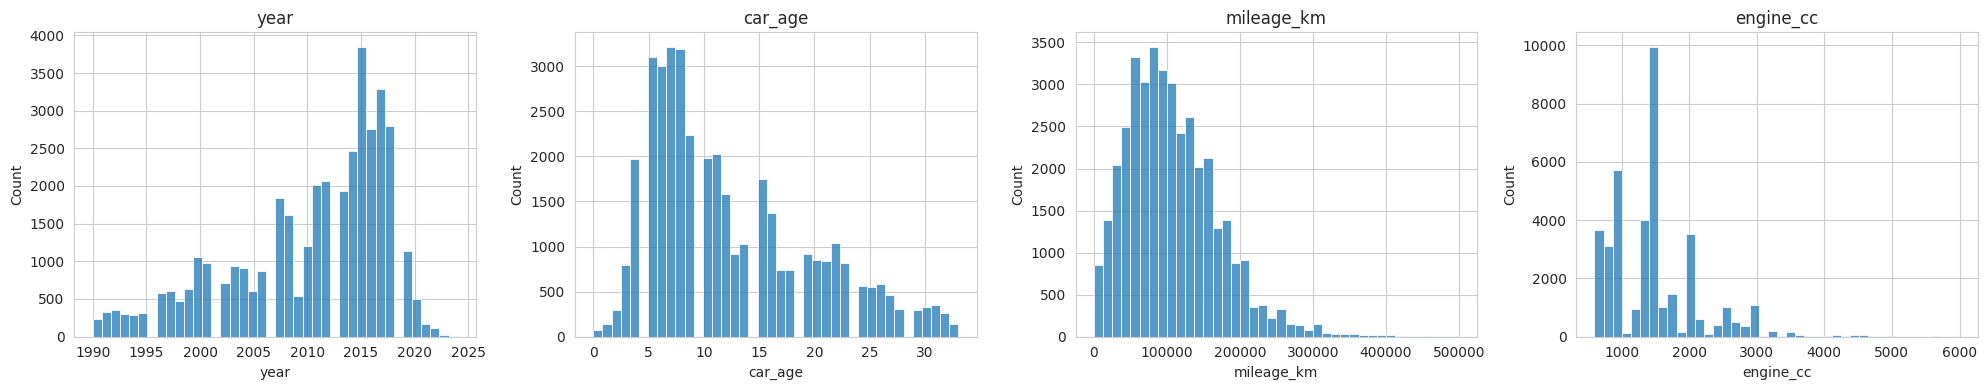

In [66]:
# Distribution of each numeric feature
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for ax, col in zip(axes, num_cols):
    sns.histplot(clean[col], bins=40, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

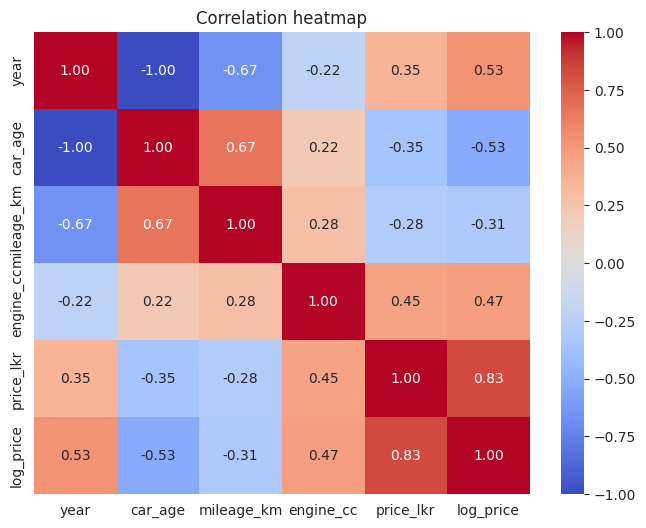

In [67]:
# Correlation heatmap
corr_data = clean[num_cols + ["price_lkr"]].copy()
corr_data["log_price"] = log_price

plt.figure(figsize=(8, 6))
sns.heatmap(corr_data.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap")
plt.show()

# Analyzing categorical features.

In [68]:
cat_cols = ["brand", "model", "condition", "transmission", "fuel_type", "body_type", "district", "seller_type"]

# Number of different values in each categorical column
clean[cat_cols].nunique()

brand            55
model           546
condition         3
transmission      3
fuel_type         3
body_type         8
district         25
seller_type       2
dtype: int64

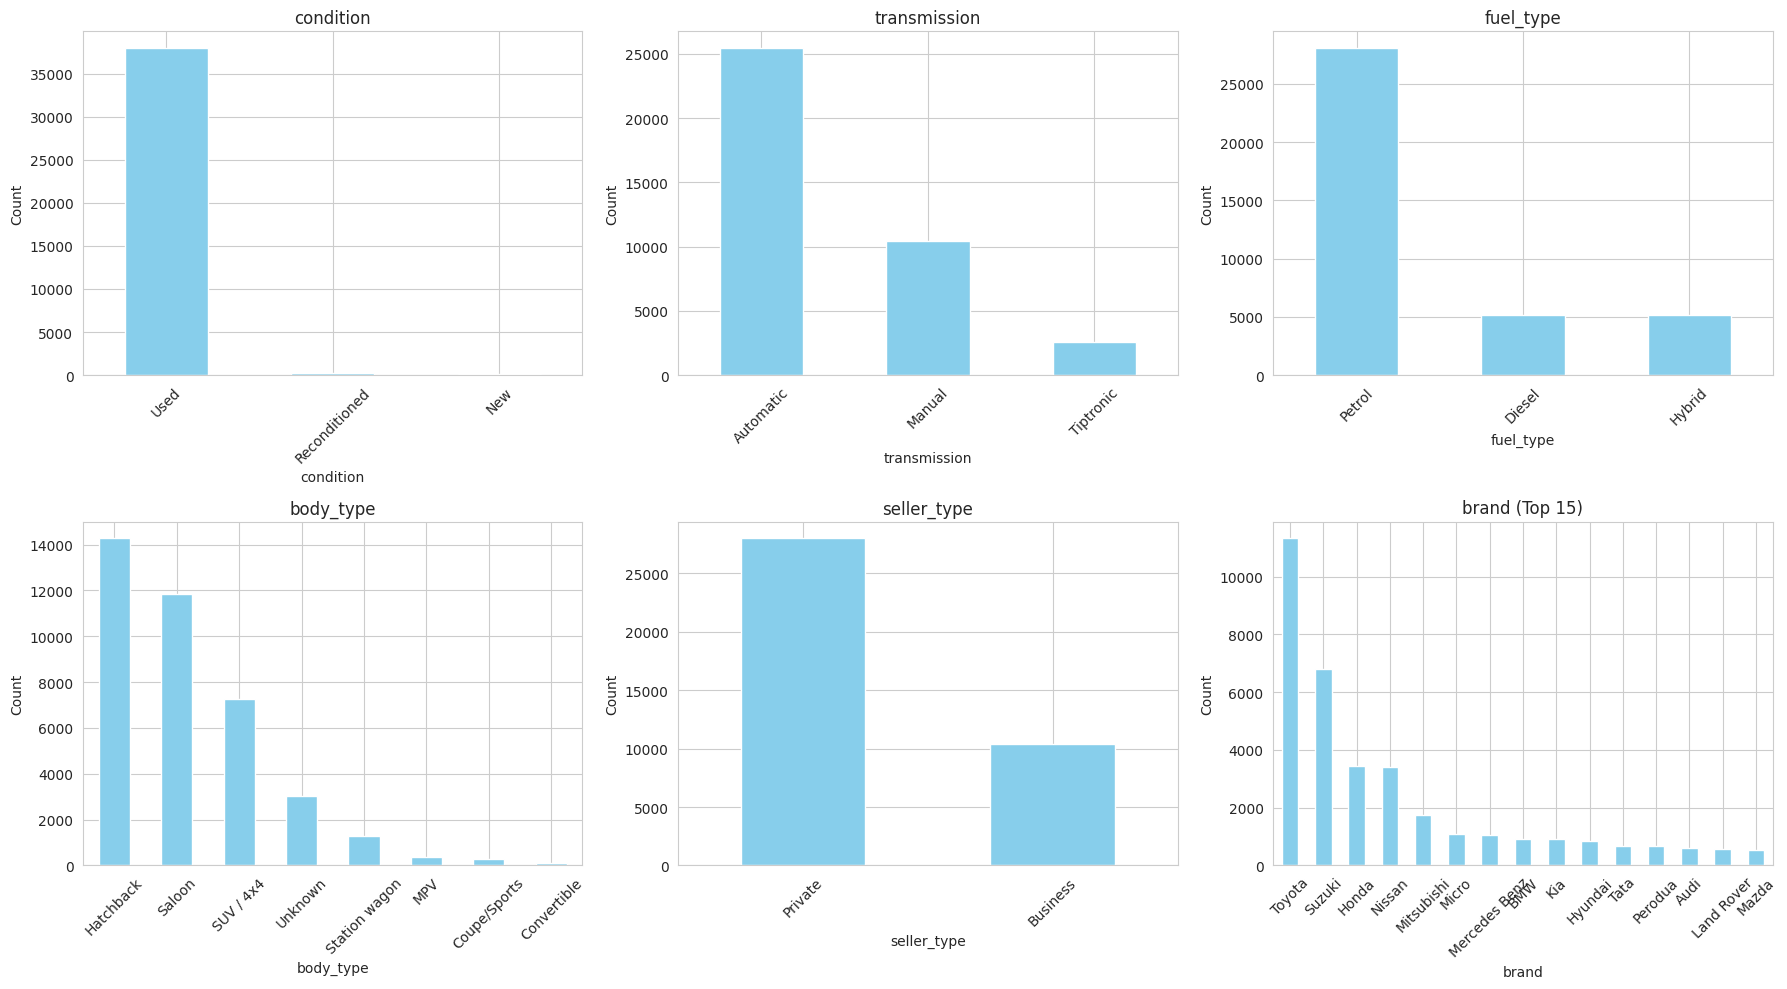

In [69]:
# Count of each category (small columns) arranged in a 2x3 grid
small_cats = ["condition", "transmission", "fuel_type", "body_type", "seller_type", "brand"]

# Create a 2x3 grid of subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Flatten the 2D array of axes to 1D for easy iteration
axes_flat = axes.flatten()

for ax, col in zip(axes_flat, small_cats):
    # For the 'brand' column, limit it to the top 15 values so the bar chart remains readable
    if col == "brand":
        clean[col].value_counts().head(15).plot(kind="bar", ax=ax, color="skyblue")
        ax.set_title("brand (Top 15)")
    else:
        clean[col].value_counts().plot(kind="bar", ax=ax, color="skyblue")
        ax.set_title(col)

    ax.tick_params(axis="x", rotation=45)
    ax.set_ylabel("Count")

plt.tight_layout()
plt.show()

In [70]:
# Median price for each category
for col in small_cats:
    print(clean.groupby(col)["price_lkr"].agg(["count", "median"]).sort_values("median"), "\n")

               count      median
condition                       
Used           38026   5100000.0
Reconditioned    273   7390000.0
New              163  11500000.0 

              count      median
transmission                   
Manual        10413   2550000.0
Automatic     25473   5975000.0
Tiptronic      2576  11147500.0 

           count     median
fuel_type                  
Petrol     28097  4360000.0
Hybrid      5171  6550000.0
Diesel      5194  7975000.0 

               count      median
body_type                       
Hatchback      14287   3990000.0
Unknown         3023   4885000.0
Saloon         11857   5075000.0
MPV              386   5200000.0
Station wagon   1270   5200000.0
Coupe/Sports     268   8175000.0
SUV / 4x4       7281  10000000.0
Convertible       90  19000000.0 

             count     median
seller_type                  
Private      28036  4500000.0
Business     10426  7300000.0 

               count      median
brand                           
Chery    

In [71]:
# How many models have fewer than 10 ads?
model_counts = clean["model"].value_counts()
print("Number of models :", len(model_counts))
print("Models with < 10 ads :", (model_counts < 10).sum())
print("Share of ads in Colombo :", round((clean["district"] == "Colombo").mean() * 100, 1), "%")
print("Share of 'Used' condition :", round((clean["condition"] == "Used").mean() * 100, 1), "%")

Number of models : 546
Models with < 10 ads : 247
Share of ads in Colombo : 48.3 %
Share of 'Used' condition : 98.9 %


# Preprocessing

In [72]:
# Take 1 random car out of data for interencing.
inference_car = clean.sample(n=1, random_state=42)

data = clean.drop(inference_car.index)

print("Cars for training and testing:", len(data))
inference_car

Cars for training and testing: 38461


,brand,model,year,car_age,mileage_km,engine_cc,condition,transmission,fuel_type,body_type,district,seller_type,price_lkr
4148,Toyota,Corolla,1990,32,150000,1600,Used,Manual,Diesel,Saloon,Jaffna,Private,1675000.0


In [73]:
# Here, "year" also had to drop since it is same information as car_age.
X = data.drop(columns=["price_lkr", "year"])
y = np.log1p(data["price_lkr"])

print("X shape:", X.shape)
print("Features:", X.columns.tolist())

X shape: (38461, 11)
Features: ['brand', 'model', 'car_age', 'mileage_km', 'engine_cc', 'condition', 'transmission', 'fuel_type', 'body_type', 'district', 'seller_type']


In [74]:
# Train test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (30768, 11)
Test : (7693, 11)


In [75]:
# Preprocessing pipeline.
# Numeric cloumns -> fill missing values with mean. Used StandardScaler.
# Categorical columns -> assumed min_frequency = 10. Categories with fewer than 10 ads in the training set are grouped into one "infrequent" column. If a totally new category is come, it goes to the "infrequent" column.

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Column types for modelling (year is removed)
num_cols = ["car_age", "mileage_km", "engine_cc"]
cat_cols = ["brand", "model", "condition", "transmission", "fuel_type", "body_type", "district", "seller_type"]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10), cat_cols)
])

# Models with hyperparameters.
Here I am going to use Linear Regression as base model, and RF, XGBoost and CatBoost as other comparission models.

In [76]:
!pip install xgboost catboost -q

In [77]:
# Linear regresison, RF, XGBoost -> use same preprocessor I used earlier.
# CatBoost -> since this gets raw categorical columns and handles them in its own way.
# All models use same train-test split, same features and same target.

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

models = {
    "Linear Regression": Pipeline([
        ("preprocess", preprocessor),
        ("model", LinearRegression())
    ]),
    "Random Forest": Pipeline([
        ("preprocess", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=300, max_depth=20, min_samples_leaf=2, max_features=0.5,
            n_jobs=-1, random_state=42))
    ]),
    "XGBoost": Pipeline([
        ("preprocess", preprocessor),
        ("model", XGBRegressor(
            n_estimators=1000, learning_rate=0.05, max_depth=8,
            subsample=0.8, colsample_bytree=0.8,
            n_jobs=-1, random_state=42))
    ]),
    "CatBoost": CatBoostRegressor(
        iterations=1500, learning_rate=0.05, depth=8, l2_leaf_reg=5,
        cat_features=cat_cols, random_seed=42, verbose=0),
}

In [78]:
# Each model lerans from X_train and log(price).
# Prdicted log prices are converted into LKR.
# Metrics used - RMSE (Average error, big mistakes count more. Lower is better), MAE (Average error in LKR. Lower is better), R2 (How much of the price differences the model explains. Closer to 1 is better)
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

y_test_rs = np.expm1(y_test)   # real test prices in rupees

results = []

for name, model in models.items():
    model.fit(X_train, y_train)

    pred_rs = np.expm1(model.predict(X_test))   # predicted prices in rupees

    results.append({
        "Model": name,
        "RMSE (Rs)": np.sqrt(mean_squared_error(y_test_rs, pred_rs)),
        "MAE (Rs)": mean_absolute_error(y_test_rs, pred_rs),
        "R²": r2_score(y_test_rs, pred_rs)
    })
    print(name, "- done")

results_hand = pd.DataFrame(results).sort_values("RMSE (Rs)").reset_index(drop=True)
results_hand.round(3)

Linear Regression - done
Random Forest - done
XGBoost - done
CatBoost - done


,Model,RMSE (Rs),MAE (Rs),R²
0,XGBoost,2325175.838,799063.975,0.927
1,Random Forest,2476278.419,835619.662,0.917
2,CatBoost,2647602.058,937840.670,0.905
3,Linear Regression,3016239.434,1073860.866,0.877


# hyperparameter Tuning.

In [79]:
# Above given hyperparam values are gussed ones. So, it cannot be guranteed those are the best. Therefore, need to tune hyperparams of selected models.
# No need to consider linear regression since it does not have hyperparams.
# Here, I have used RandomizedSearchCV with n_iter = 10. Each combination is checked with cv = 3. Therefore total counts of trainings of each model = 10*3 = 30.
# Try to find -> lowest RMSE on log(price).
# Select the combination (of hyperparam values) with the lowest average RMSE, then train the model again on the whole train set with these values.

from sklearn.model_selection import RandomizedSearchCV

param_lists = {
    "Random Forest": {
        "model__n_estimators": [200, 300, 500],
        "model__max_depth": [10, 20, 30, None],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": [0.3, 0.5, 0.7],
    },
    "XGBoost": {
        "model__n_estimators": [500, 1000, 1500],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [4, 6, 8, 10],
        "model__subsample": [0.7, 0.8, 1.0],
        "model__colsample_bytree": [0.5, 0.7, 0.9],
        "model__min_child_weight": [1, 3, 5],
    },
    "CatBoost": {
        "iterations": [500, 1000, 1500],
        "learning_rate": [0.03, 0.05, 0.1],
        "depth": [4, 6, 8, 10],
        "l2_leaf_reg": [1, 3, 5, 9],
    },
}

In [80]:
# RF and XGBoost use the pipeline created previously.
# CatBoost starts from a new CatBoost model.
base_models = {
    "Random Forest": models["Random Forest"],
    "XGBoost": models["XGBoost"],
    "CatBoost": CatBoostRegressor(random_seed=42, verbose=0),   # cat_features is given in fit()
}

tuned_models = {}
tuning_results = []

for name, params in param_lists.items():
    search = RandomizedSearchCV(
        base_models[name], params,
        n_iter=10, cv=3,
        scoring="neg_root_mean_squared_error",
        random_state=42
    )

    if name == "CatBoost":
        search.fit(X_train, y_train, cat_features=cat_cols)
    else:
        search.fit(X_train, y_train)

    tuned_models[name] = search.best_estimator_   # already trained on the whole train set

    best_values = {k.replace("model__", ""): v for k, v in search.best_params_.items()}
    tuning_results.append({
        "Model": name,
        "Best CV RMSE (log price)": -search.best_score_,   # sklearn gives negative RMSE
        "Best values": best_values
    })

    print(name, "- done the Search.")

Random Forest - done the Search.
XGBoost - done the Search.
CatBoost - done the Search.


In [81]:
# Check best values found.
tuning_table = pd.DataFrame(tuning_results)
pd.set_option("display.max_colwidth", None)
tuning_table.round(4)

,Model,Best CV RMSE (log price),Best values
0,Random Forest,0.2069,"{'n_estimators': 500, 'min_samples_leaf': 1, 'max_features': 0.3, 'max_depth': None}"
1,XGBoost,0.1999,"{'subsample': 0.8, 'n_estimators': 1500, 'min_child_weight': 3, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.5}"
2,CatBoost,0.2047,"{'learning_rate': 0.03, 'l2_leaf_reg': 1, 'iterations': 1500, 'depth': 10}"


# Final Comparison & Best Model Selection .

In [82]:
# Test the tuned models.
results = []

for name, model in tuned_models.items():
    pred_rs = np.expm1(model.predict(X_test))   # predicted prices in rupees

    results.append({
        "Model": name,
        "RMSE (Rs)": np.sqrt(mean_squared_error(y_test_rs, pred_rs)),
        "MAE (Rs)": mean_absolute_error(y_test_rs, pred_rs),
        "R²": r2_score(y_test_rs, pred_rs)
    })

results_tuned = pd.DataFrame(results)

# Put the results which I used randomly gussed hyperparam values and the tuned results together
hand = results_hand.copy()
hand["Version"] = np.where(hand["Model"] == "Linear Regression", "Baseline", "Hand-set")
results_tuned["Version"] = "Tuned"

all_results = (pd.concat([hand, results_tuned])
               .sort_values("RMSE (Rs)")
               .reset_index(drop=True))
all_results = all_results[["Model", "Version", "RMSE (Rs)", "MAE (Rs)", "R²"]]
all_results.round(3)

,Model,Version,RMSE (Rs),MAE (Rs),R²
0,XGBoost,Hand-set,2325175.838,799063.975,0.927
1,XGBoost,Tuned,2338714.254,808265.268,0.926
2,Random Forest,Tuned,2435817.264,788844.238,0.920
3,Random Forest,Hand-set,2476278.419,835619.662,0.917
4,CatBoost,Tuned,2567339.157,891498.217,0.911
5,CatBoost,Hand-set,2647602.058,937840.670,0.905
6,Linear Regression,Baseline,3016239.434,1073860.866,0.877


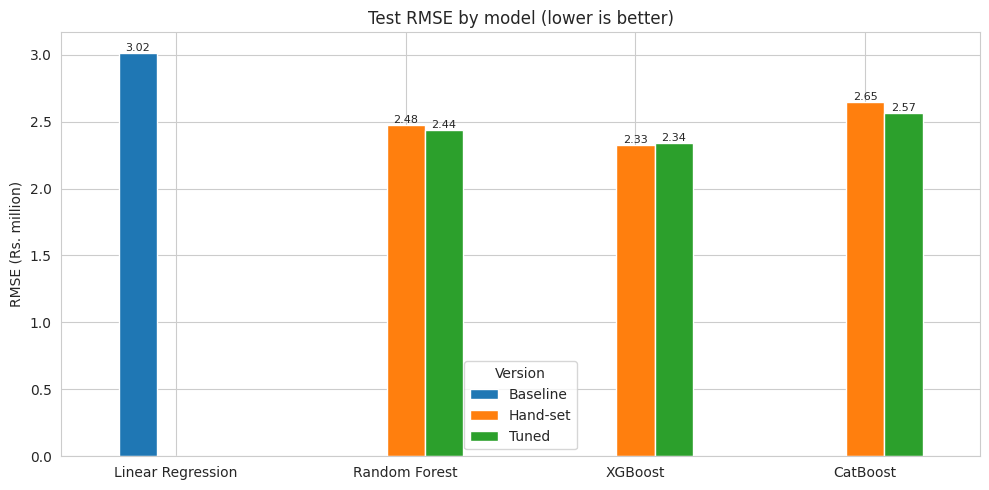

In [83]:
# Bar charts -> before model tuning & after model tunign RMSE values.
chart = all_results.pivot(index="Model", columns="Version", values="RMSE (Rs)") / 1_000_000
chart = chart.reindex(["Linear Regression", "Random Forest", "XGBoost", "CatBoost"])
chart = chart[[c for c in ["Baseline", "Hand-set", "Tuned"] if c in chart.columns]]

ax = chart.plot(kind="bar", figsize=(10, 5), rot=0)
ax.set_title("Test RMSE by model (lower is better)")
ax.set_ylabel("RMSE (Rs. million)")
ax.set_xlabel("")
for container in ax.containers:
    labels = [f"{v:.2f}" if v > 0 else "" for v in container.datavalues]   # no label for empty bars
    ax.bar_label(container, labels=labels, fontsize=8)

plt.tight_layout()
plt.show()

In [84]:
# Select best model.
best = all_results.iloc[0]
best_name, best_version = best["Model"], best["Version"]

if best_version == "Tuned":
    final_model = tuned_models[best_name]
else:
    final_model = models[best_name]

print("[16.3] Best model :", best_name, "(" + best_version + ")")
print("[16.3] Test RMSE : Rs", f"{best['RMSE (Rs)']:,.0f}")
print("[16.3] Test MAE : Rs", f"{best['MAE (Rs)']:,.0f}")
print("[16.3] Test R² :", round(best["R²"], 3))

[16.3] Best model : XGBoost (Hand-set)
[16.3] Test RMSE : Rs 2,325,176
[16.3] Test MAE : Rs 799,064
[16.3] Test R² : 0.927


# Explaining Best Model with SHAP.

In [85]:
!pip install shap -q
import shap

In [86]:
# Choose the cars to explain.
X_shap = X_test.sample(n=2000, random_state=42)    # global view
car = X_test.sample(n=1, random_state=42)          # local view: one typical test car

print("[17.2] Cars for the global view:", len(X_shap))
car.T

[17.2] Cars for the global view: 2000


,7150
brand,Mitsubishi
model,Lancer
car_age,24
mileage_km,106009
engine_cc,1500
condition,Used
transmission,Automatic
fuel_type,Petrol
body_type,Saloon
district,Anuradhapura


In [87]:
# Calculate SHAP values.
features = X_test.columns.tolist()

def get_shap_values(model, X_part):
    """Return SHAP values (one column per original feature) and the base value, in log(price)."""
    if isinstance(model, Pipeline):
        pre = model.named_steps["preprocess"]
        est = model.named_steps["model"]
        if isinstance(est, LinearRegression):
            raise ValueError("[17.3] TreeExplainer works only for tree models, not Linear Regression.")

        X_pre = pre.transform(X_part)
        if not isinstance(est, XGBRegressor) and hasattr(X_pre, "toarray"):
            X_pre = X_pre.toarray()     # Random Forest needs dense data

        explainer = shap.TreeExplainer(est)
        values = explainer.shap_values(X_pre)
        values = values.toarray() if hasattr(values, "toarray") else np.asarray(values)

        # Add up the one-hot columns of each original feature
        names = pre.get_feature_names_out()
        grouped = np.zeros((len(X_part), len(features)))
        for j, f in enumerate(features):
            cols = np.array([n == "num__" + f or n.startswith("cat__" + f + "_") for n in names])
            grouped[:, j] = values[:, cols].sum(axis=1)
    else:
        explainer = shap.TreeExplainer(model)      # CatBoost
        grouped = np.asarray(explainer.shap_values(X_part))

    base_value = float(np.ravel(explainer.expected_value)[0])
    return grouped, base_value

shap_values, base_value = get_shap_values(final_model, X_shap)

# Check: base value + sum of SHAP values should equal the model's prediction (in log)
diff = np.abs(base_value + shap_values.sum(axis=1) - final_model.predict(X_shap)).max()
print("Explained model :", best_name, "(" + best_version + ")")
print("Base value (log) :", round(base_value, 3), "→ about Rs", f"{np.expm1(base_value):,.0f}")
print("Check (max difference) :", round(diff, 6), "(should be close to 0)")

Explained model : XGBoost (Hand-set)
Base value (log) : 15.486 → about Rs 5,314,160
Check (max difference) : 4.5e-05 (should be close to 0)


/usr/local/lib/python3.13/dist-packages/numpy/lib/_nanfunctions_impl.py:1437: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


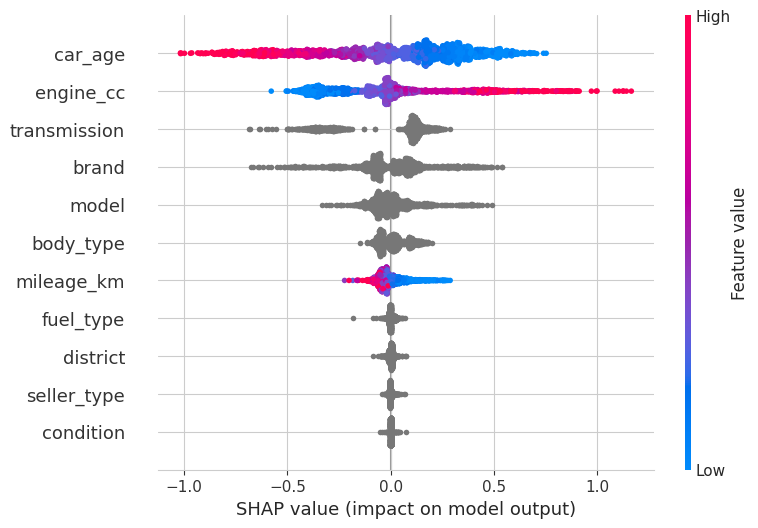

In [88]:
# Global view - beeswarm plt
plot_data = X_shap.copy()
for c in cat_cols:
    plot_data[c] = np.nan # no colour for categorical features

shap_exp = shap.Explanation(
    values=shap_values,
    base_values=np.full(len(shap_values), base_value),
    data=plot_data.astype(float).values,
    feature_names=features
)

shap.plots.beeswarm(shap_exp, max_display=11)

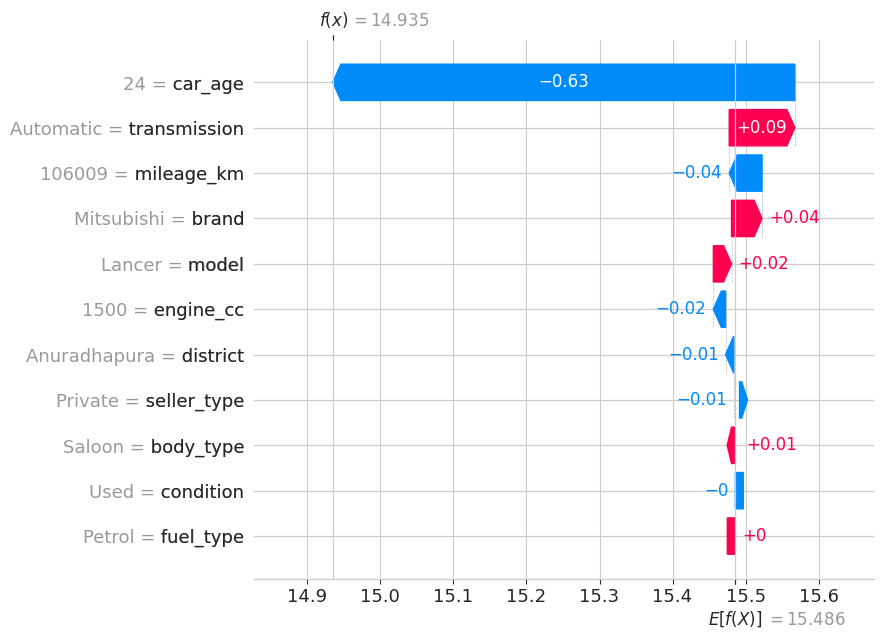

Real price : Rs 3,990,000
Predicted price : Rs 3,062,954


In [89]:
# Local view - waterfall plot for one car.
car_values, car_base = get_shap_values(final_model, car)

car_exp = shap.Explanation(
    values=car_values[0],
    base_values=car_base,
    data=car.iloc[0].values,
    feature_names=features
)

shap.plots.waterfall(car_exp, max_display=11)

print("Real price : Rs", f"{np.expm1(y_test.loc[car.index[0]]):,.0f}")
print("Predicted price : Rs", f"{np.expm1(final_model.predict(car))[0]:,.0f}")

# Explaining same car with LIME.

In [90]:
!pip install lime -q
from lime.lime_tabular import LimeTabularExplainer

In [91]:
# Convert text categories to code.
categories = {c: sorted(pd.concat([X_train[c], car[c]]).astype(str).unique()) for c in cat_cols}
cat_index = [features.index(c) for c in cat_cols]

def to_codes(df):
    """Text categories → number codes (for LIME)."""
    out = df[features].copy()
    for c in cat_cols:
        out[c] = pd.Categorical(out[c].astype(str), categories=categories[c]).codes
    return out.astype(float).values

def from_codes(arr):
    """Number codes → text categories (for the model)."""
    df = pd.DataFrame(arr, columns=features)
    for c in cat_cols:
        df[c] = [categories[c][int(round(v))] for v in df[c]]
    return df

def predict_for_lime(arr):
    return final_model.predict(from_codes(arr))   # log(price)

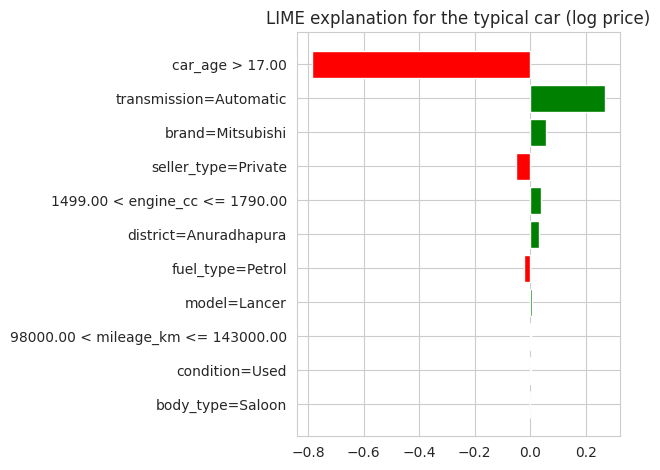

In [92]:
# Explain the car.
lime_explainer = LimeTabularExplainer(
    training_data=to_codes(X_train),
    feature_names=features,
    categorical_features=cat_index,
    categorical_names={i: categories[c] for i, c in zip(cat_index, cat_cols)},
    mode="regression",
    discretize_continuous=True,
    random_state=42
)

lime_exp = lime_explainer.explain_instance(
    to_codes(car)[0],
    predict_for_lime,
    num_features=11
)

fig = lime_exp.as_pyplot_figure()
plt.title("LIME explanation for the typical car (log price)")
plt.tight_layout()
plt.show()

In [93]:
# SHAP vs LIME for same car.
lime_weights = dict(lime_exp.as_map()[1])     # {feature index: weight}

compare = pd.DataFrame({
    "Feature": features,
    "Car value": car.iloc[0].values,
    "SHAP (log)": car_values[0],
    "LIME (log)": [lime_weights.get(i, 0.0) for i in range(len(features))],
})
compare["Same direction?"] = np.where(np.sign(compare["SHAP (log)"]) == np.sign(compare["LIME (log)"]), "Yes", "No")
compare["SHAP rank"] = compare["SHAP (log)"].abs().rank(ascending=False).astype(int)
compare["LIME rank"] = compare["LIME (log)"].abs().rank(ascending=False).astype(int)

compare = compare.sort_values("SHAP rank").reset_index(drop=True)
compare.round(3)

,Feature,Car value,SHAP (log),LIME (log),Same direction?,SHAP rank,LIME rank
0,car_age,24,-0.633,-0.788,Yes,1,1
1,transmission,Automatic,0.090,0.271,Yes,2,2
2,mileage_km,106009,-0.045,0.004,No,3,9
3,brand,Mitsubishi,0.042,0.058,Yes,4,3
4,model,Lancer,0.025,0.006,Yes,5,8
5,engine_cc,1500,-0.017,0.037,No,6,5
6,district,Anuradhapura,-0.011,0.030,No,7,6
7,seller_type,Private,-0.008,-0.051,Yes,8,4
8,body_type,Saloon,0.006,-0.001,No,9,11
9,condition,Used,-0.000,0.004,No,10,10


# Inference on a new car & saving the model.

In [94]:
# Save the best model.
import pickle
import os

pickle.dump(final_model, open("model.pkl", "wb"))

print("Saved model :", best_name, "(" + best_version + ")")
print("File : model.pkl")
print("File size (MB) :", round(os.path.getsize("model.pkl") / 1_000_000, 1))

Saved model : XGBoost (Hand-set)
File : model.pkl
File size (MB) : 5.8


In [95]:
# Load the file and predict the car which I kept aside earlier.
loaded_model = pickle.load(open("model.pkl", "rb"))

new_car = inference_car.drop(columns=["price_lkr", "year"])   # same features as in training
real_price = inference_car["price_lkr"].iloc[0]
predicted_price = np.expm1(loaded_model.predict(new_car))[0]
error_pct = (predicted_price - real_price) / real_price * 100

print("Real price (saved car): Rs", f"{real_price:,.0f}")
print("Predicted price (saved car) : Rs", f"{predicted_price:,.0f}")
print("Error (saved car) :", f"{error_pct:+.1f} %")
new_car.T

Real price (saved car): Rs 1,675,000
Predicted price (saved car) : Rs 1,683,552
Error (saved car) : +0.5 %


,4148
brand,Toyota
model,Corolla
car_age,32
mileage_km,150000
engine_cc,1600
condition,Used
transmission,Manual
fuel_type,Diesel
body_type,Saloon
district,Jaffna


In [96]:
import sys
import sklearn, xgboost

print("[19.3 versions] python       :", sys.version.split()[0])
print("[19.3 versions] scikit-learn :", sklearn.__version__)
print("[19.3 versions] xgboost      :", xgboost.__version__)
print("[19.3 versions] pandas       :", pd.__version__)
print("[19.3 versions] numpy        :", np.__version__)

[19.3 versions] python       : 3.13.15
[19.3 versions] scikit-learn : 1.6.1
[19.3 versions] xgboost      : 3.4.1
[19.3 versions] pandas       : 2.3.3
[19.3 versions] numpy        : 2.1.3


# Notes

### Good practice followed
- **Cleaning before the split** used only fixed rules (no values learned from the data). Duplicate ads were removed to avoid the same car being in both train and test sets.
- **All preprocessing is inside a pipeline**, so it learns only from the training set (no data leakage).
- **One car was kept aside** before the split and used only for inference.
- **Tuning used the train set only** (3-fold cross-validation). The test set was used only for the final comparison.
- **Checks** were added: SHAP values add up to the model prediction, and the saved `model.pkl` was loaded and used again.

### Limitations
- **Market period:** the ads are from Sept 2022 – Apr 2023, during the vehicle import ban and the economic crisis. Vehicle imports restarted in 2025, so today's prices are different. The model may not predict present or future prices well without **retraining** on recent data.
- **Scope:** only cars from **1990–2024**, priced **Rs 0.5M – 100M**, with **petrol, diesel or hybrid** engines. Vintage, electric and very expensive cars were removed.
- **Unbalanced data:** about 99% of the ads are "Used" cars and about 48% are from Colombo, so the model has little data for new or reconditioned cars and for some districts.
- **Rare models and brands** (fewer than 10 ads in the training set) are grouped as "infrequent", so the model cannot tell them apart.
- **Hyperparameters:** the hand-set values are reasonable, not proven best. The search tried only 10 combinations with 3-fold cross-validation (the lecture example used 5 folds), to save time.
- **Tuning used RMSE on log(price)**, while the final choice used **RMSE in rupees**. They are close, but not exactly the same.
- **The inference check uses only one car**, which is an unusual, old car. One car cannot prove the model's accuracy.
- **Explanations are not causes:** SHAP and LIME explain how the **model** uses the features, not what truly causes car prices.